In [10]:
%pip install xgboost lightgbm

Note: you may need to restart the kernel to use updated packages.


In [11]:
# Import libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Model saving
import joblib
import os

print("All 7 classification model libraries imported successfully!")




All 7 classification model libraries imported successfully!


In [12]:
# Loading the feature-engineered dataset

df = pd.read_csv(
    "data/charging_records_featured.csv"
)

print("Dataset loaded successfully")

print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully
Dataset shape: (72826, 20)


,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand,CalculatedDuration,Hour,DayOfWeek,Month,Year,IsWeekend,TimeOfDay
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54:00,2022-09-15 23:59:00,185,20.36,185.0,20,3,9,2022,0,Evening
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01:00,2022-09-14 21:31:00,90,10.19,90.0,20,2,9,2022,0,Evening
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54:00,2022-09-14 19:54:00,60,6.78,60.0,18,2,9,2022,0,Evening
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,00:16:42,2022-09-29 18:32:00,2022-09-30 00:16:00,344,37.65,344.0,18,3,9,2022,0,Evening
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,00:30:14,2022-09-25 19:30:00,2022-09-26 00:30:00,300,33.81,300.0,19,6,9,2022,1,Evening


In [13]:
# Selecting the input features-----We need to tell Python which columns should be used to make predictions.

features = [
    "ChargerCompany",
    "Location",
    "ChargerType",
    "Hour",
    "DayOfWeek",
    "Month",
    "IsWeekend"
]


print("Selected input features:")
print(features)

Selected input features:
['ChargerCompany', 'Location', 'ChargerType', 'Hour', 'DayOfWeek', 'Month', 'IsWeekend']


In [14]:
# Split the data into training and testing datasets (Train-Test Split)

model_df = df[
    features + ["StartDatetime", "Demand"]
].copy()

model_df["StartDatetime"] = pd.to_datetime(
    model_df["StartDatetime"],
    errors="coerce"
)

model_df = (
    model_df
    .dropna(subset=features + ["StartDatetime", "Demand"])
    .sort_values("StartDatetime")
    .reset_index(drop=True)
)

split_index = int(len(model_df) * 0.80)

train_df = model_df.iloc[:split_index].copy()

test_df = model_df.iloc[split_index:].copy()

X_train = train_df[features]

X_test = test_df[features]

print("Training records:", len(X_train))

print("Testing records:", len(X_test))

print("\nTraining date range:")
print(train_df["StartDatetime"].min(),
      "to",
      train_df["StartDatetime"].max())

print("\nTesting date range:")
print(test_df["StartDatetime"].min(),
      "to",
      test_df["StartDatetime"].max())

Training records: 58260
Testing records: 14566

Training date range:
2021-09-30 17:14:00 to 2022-07-30 19:09:00

Testing date range:
2022-07-30 19:09:00 to 2022-09-30 23:11:00


In [15]:
# Create the classification target

demand_threshold = train_df["Demand"].median()

print("Median Demand Threshold:", demand_threshold)

Median Demand Threshold: 14.2


In [16]:
# Creating the Target Table

y_train = (
    train_df["Demand"] >= demand_threshold
).astype(int)

y_test = (
    test_df["Demand"] >= demand_threshold
).astype(int)

print("Training target distribution:")

print(y_train.value_counts())

print("\nTesting target distribution:")

print(y_test.value_counts())

Training target distribution:
Demand
1    29143
0    29117
Name: count, dtype: int64

Testing target distribution:
Demand
0    7464
1    7102
Name: count, dtype: int64


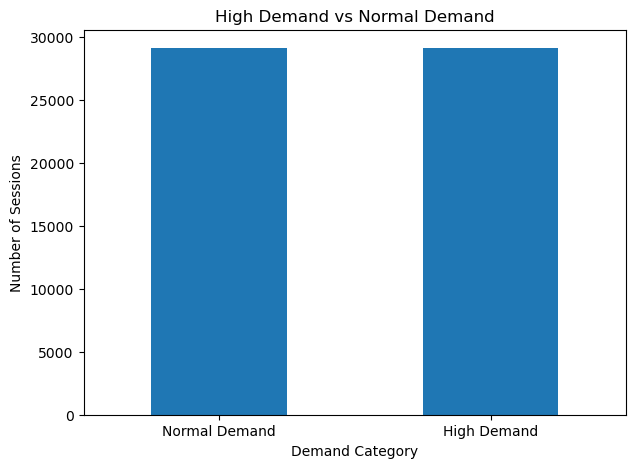

In [17]:
# Visualise the target distribution

category_counts = pd.Series({
    "Normal Demand": (y_train == 0).sum(),
    "High Demand": (y_train == 1).sum()
})

plt.figure(figsize=(7, 5))

category_counts.plot(
    kind="bar",
    rot=0
)

plt.title("High Demand vs Normal Demand")

plt.xlabel("Demand Category")

plt.ylabel("Number of Sessions")

plt.show()

In [18]:
# Create the preprocessing pipeline

categorical_features = [
    "ChargerCompany",
    "Location",
    "ChargerType"
]

numerical_features = [
    "Hour",
    "DayOfWeek",
    "Month",
    "IsWeekend"
]




In [19]:
# Creating the categorical preprocessing


categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

In [20]:
# Creating the numerical preprocessing

numerical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)


In [21]:
# Combining both


preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            categorical_transformer,
            categorical_features
        ),
        (
            "numerical",
            numerical_transformer,
            numerical_features
        )
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [22]:
# Create all seven classification models

classifiers = {

    # Model 1: Logistic Regression
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    # Model 2: Decision Tree
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    # Model 3: Random Forest
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    # Model 4: K-Nearest Neighbors
    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    # Model 5: Support Vector Machine
    "SVM": LinearSVC(
        C=1.0,
        max_iter=5000,
        random_state=42
    ),

    # Model 6: XGBoost
    "XGBoost": XGBClassifier(
        n_estimators=100,
        max_depth=5,
        learning_rate=0.1,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ),

    # Model 7: LightGBM
    "LightGBM": LGBMClassifier(
        n_estimators=100,
        max_depth=-1,
        learning_rate=0.1,        
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

}

print("Total classification models:", len(classifiers))

for name in classifiers:
    print(name)

Total classification models: 7
Logistic Regression
Decision Tree
Random Forest
KNN
SVM
XGBoost
LightGBM


In [24]:
# Train all seven models

trained_classifiers = {}

classification_results = []

for name, model in classifiers.items():

    print("\nTraining:", name)

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    # Train model
    pipeline.fit(X_train, y_train)

    # Predict test records
    predictions = pipeline.predict(X_test)

    # handle probability or decision scores
    if hasattr(pipeline, "predict_proba"):

        scores = pipeline.predict_proba(X_test)[:, 1]

    else:
        scores = pipeline.decision_function(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(
        y_test, predictions
    )

    precision = precision_score(
        y_test, predictions,
        zero_division=0
    )

    recall = recall_score(
        y_test, predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_test, predictions,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_test, probabilities
    )

    # Store results
    classification_results.append({

        "Model": name,

        "Accuracy": accuracy,

        "Precision": precision,

        "Recall": recall,

        "F1 Score": f1,

        "ROC AUC": roc_auc

    })

    # Store trained model
    trained_classifiers[name] = pipeline

    print(name, "training completed successfully!")

print("\nAll seven classification models trained successfully!")


Training: Logistic Regression
Logistic Regression training completed successfully!

Training: Decision Tree
Decision Tree training completed successfully!

Training: Random Forest
Random Forest training completed successfully!

Training: KNN
KNN training completed successfully!

Training: SVM
SVM training completed successfully!

Training: XGBoost
XGBoost training completed successfully!

Training: LightGBM
LightGBM training completed successfully!

All seven classification models trained successfully!


In [25]:
# Compare all seven models

classification_results_df = pd.DataFrame(
    classification_results
)

classification_results_df = (
    classification_results_df
    .sort_values(
        by="F1 Score",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    classification_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "ROC AUC": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,LightGBM,0.6431,0.6160,0.7113,0.6603,0.6243
1,XGBoost,0.6351,0.6099,0.6983,0.6511,0.6243
2,SVM,0.6168,0.5909,0.6960,0.6392,0.6243
3,Logistic Regression,0.6170,0.5914,0.6935,0.6384,0.6243
4,KNN,0.5961,0.5816,0.6114,0.5961,0.6243
5,Random Forest,0.5886,0.5732,0.6112,0.5916,0.6243
6,Decision Tree,0.5757,0.5705,0.5248,0.5467,0.6243


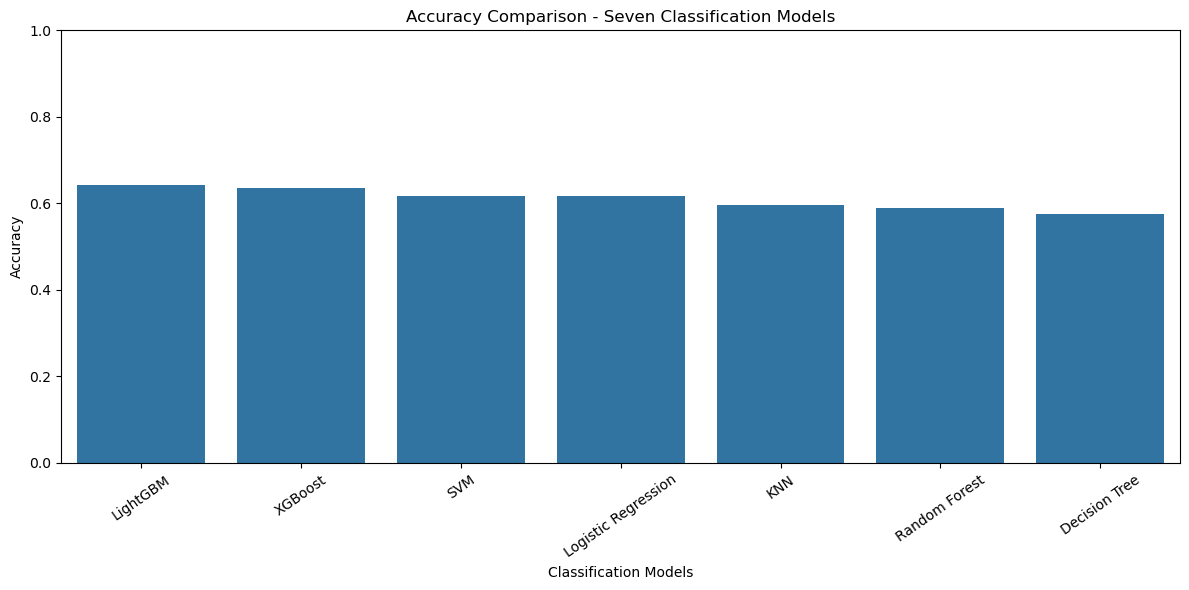

In [27]:
# Visualise model comparison

# Chart 1: Accuracy comparison

plt.figure(figsize=(12, 6))

sns.barplot(
    data=classification_results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Accuracy Comparison - Seven Classification Models")
plt.xlabel("Classification Models")
plt.ylabel("Accuracy")
plt.xticks(rotation=35)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

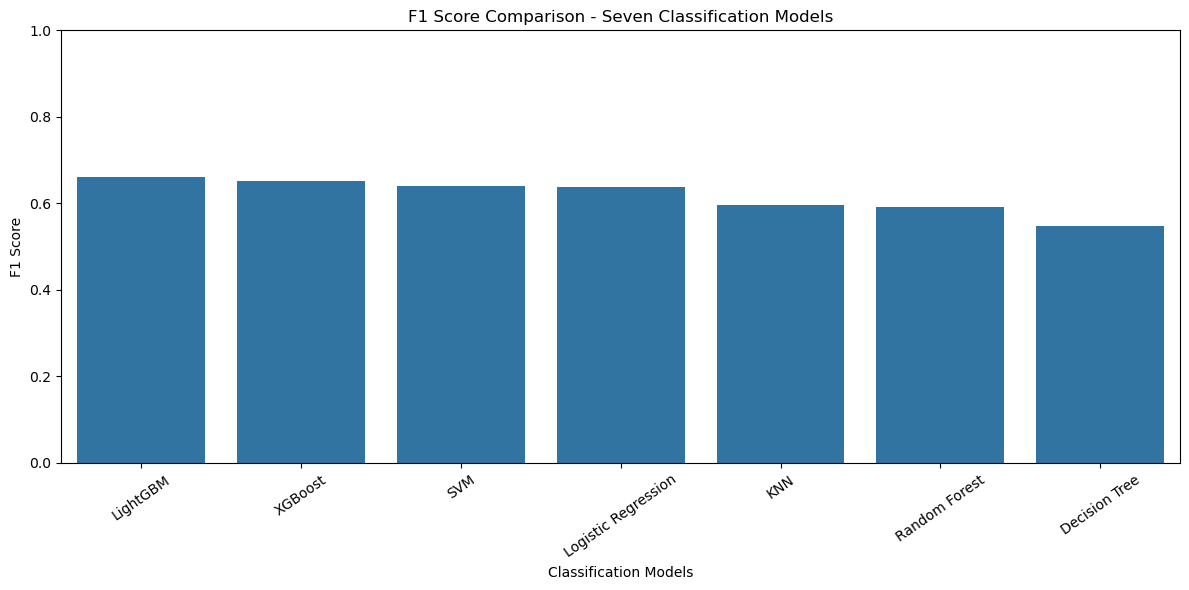

In [28]:
# Chart 2: F1 Score comparison

plt.figure(figsize=(12, 6))

sns.barplot(
    data=classification_results_df,
    x="Model",
    y="F1 Score"
)

plt.title("F1 Score Comparison - Seven Classification Models")
plt.xlabel("Classification Models")
plt.ylabel("F1 Score")
plt.xticks(rotation=35)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

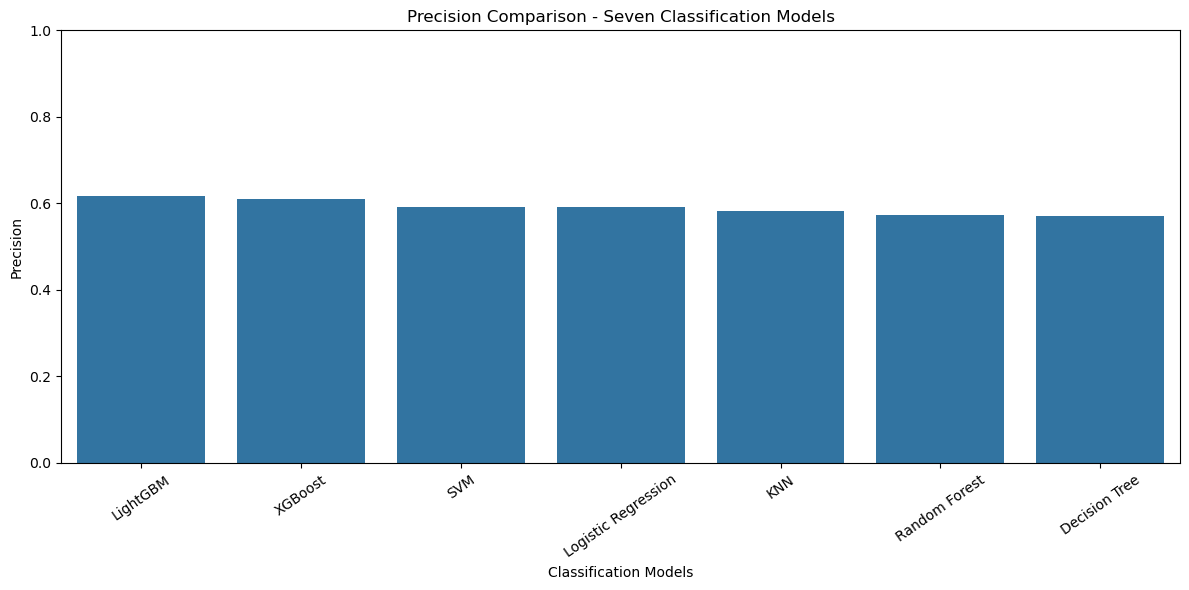

In [29]:
# Chart 3: Precision comparison

plt.figure(figsize=(12, 6))

sns.barplot(
    data=classification_results_df,
    x="Model",
    y="Precision"
)

plt.title("Precision Comparison - Seven Classification Models")
plt.xlabel("Classification Models")
plt.ylabel("Precision")
plt.xticks(rotation=35)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

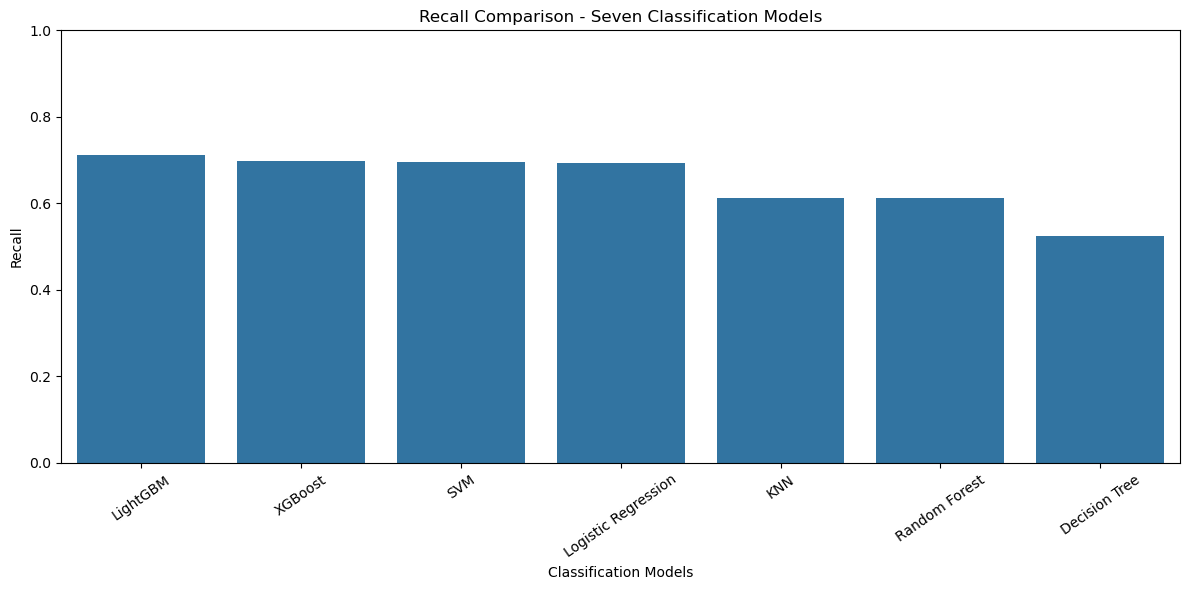

In [30]:
# Chart 4: Recall comparison

plt.figure(figsize=(12, 6))

sns.barplot(
    data=classification_results_df,
    x="Model",
    y="Recall"
)

plt.title("Recall Comparison - Seven Classification Models")
plt.xlabel("Classification Models")
plt.ylabel("Recall")
plt.xticks(rotation=35)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

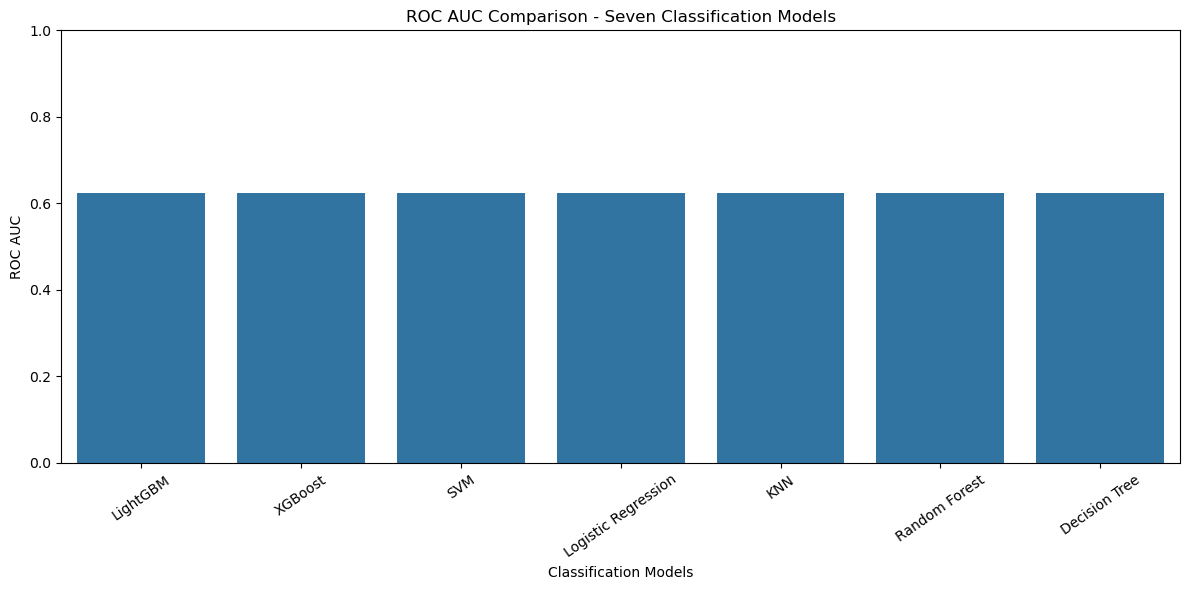

In [31]:
# Chart 5: Recall comparison

plt.figure(figsize=(12, 6))

sns.barplot(
    data=classification_results_df,
    x="Model",
    y="ROC AUC"
)

plt.title("ROC AUC Comparison - Seven Classification Models")
plt.xlabel("Classification Models")
plt.ylabel("ROC AUC")
plt.xticks(rotation=35)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [32]:
# Identify the best classification model

best_classifier_name = (
    classification_results_df.iloc[0]["Model"]
)

best_classifier = trained_classifiers[
    best_classifier_name
]

print("Best Classification Model:", best_classifier_name)

print("\nBest Model Performance:")

display(
    classification_results_df.head(1)
)

Best Classification Model: LightGBM

Best Model Performance:


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,LightGBM,0.643073,0.616022,0.711349,0.660263,0.624331


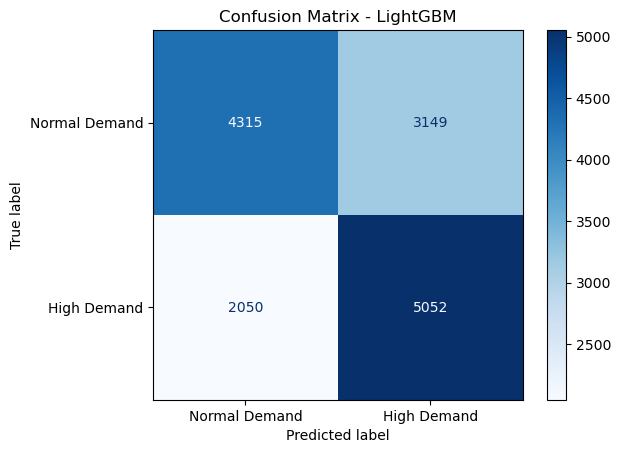

In [33]:
# Generate the confusion matrix

best_predictions = best_classifier.predict(X_test)

cm = confusion_matrix(
    y_test,
    best_predictions
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Normal Demand",
        "High Demand"
    ]
).plot(cmap="Blues")

plt.title(
    "Confusion Matrix - " + best_classifier_name
)

plt.show()

In [34]:
# Generate the classification report

print(
    classification_report(
        y_test,
        best_predictions,
        target_names=[
            "Normal Demand",
            "High Demand"
        ]
    )
)

               precision    recall  f1-score   support

Normal Demand       0.68      0.58      0.62      7464
  High Demand       0.62      0.71      0.66      7102

     accuracy                           0.64     14566
    macro avg       0.65      0.64      0.64     14566
 weighted avg       0.65      0.64      0.64     14566



In [35]:
# Save all seven trained models

os.makedirs("models", exist_ok=True)

for name, model in trained_classifiers.items():

    filename = (
        name.lower().replace(" ", "_")
        + "_pipeline.joblib"
    )

    filepath = os.path.join(
        "models",
        filename
    )

    joblib.dump(model, filepath)

    print("Saved:", filename)

# Save classification threshold
joblib.dump(
    demand_threshold,
    "models/demand_threshold.joblib"
)

# Save model comparison results
classification_results_df.to_csv(
    "models/classification_model_comparison.csv",
    index=False
)

print("\nAll seven classification models saved successfully!")

Saved: logistic_regression_pipeline.joblib
Saved: decision_tree_pipeline.joblib
Saved: random_forest_pipeline.joblib
Saved: knn_pipeline.joblib
Saved: svm_pipeline.joblib
Saved: xgboost_pipeline.joblib
Saved: lightgbm_pipeline.joblib

All seven classification models saved successfully!
